# Calidad del aire — Modelo 3: Support Vector Regression (SVR Kernel RBF) sobre CO(GT)

Dataset: **Air Quality (UCI)** (`AirQualityUCI.csv`). Objetivo: predecir la concentración de monóxido de carbono `CO(GT)` a partir de las lecturas de los sensores y la hora/día.

Modelo: **Regresión por Vectores de Soporte (`SVR` con Kernel RBF y `StandardScaler`)**, seleccionado por su eficacia para modelar curvas físico-químicas continuas y suaves de calibración de sensores. Métricas estandarizadas: **MAE, MSE, RMSE, R² (entrenamiento y prueba) y MAPE**.

## 0. Configuración: ubicación del CSV
**Opción A (por defecto):** sube `AirQualityUCI.csv` desde el panel de archivos (ícono de carpeta a la izquierda). Ojo: se borra cada vez que se reinicia la sesión.

**Opción B:** tenerlo en Google Drive. Descomenta las líneas de Drive y ajusta la ruta.

In [3]:
ruta = "AirQualityUCI.csv"



## 1. Carga de datos

In [4]:
import pandas as pd
import numpy as np

#carga el archivo
df = pd.read_csv(ruta, sep=";")
#muestra las primeras 5 filas para comprobar que se cargó correctamente.
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,"2,6",1360.0,150.0,"11,9",1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN
1,10/03/2004,19.00.00,2,1292.0,112.0,"9,4",955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,NaN
2,10/03/2004,20.00.00,"2,2",1402.0,88.0,"9,0",939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN
3,10/03/2004,21.00.00,"2,2",1376.0,80.0,"9,2",948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN
4,10/03/2004,22.00.00,"1,6",1272.0,51.0,"6,5",836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN


## 2. Limpieza de datos
Valores faltantes (`-200` → `NaN`), conversión de tipos, eliminación de columnas inútiles e imputación con la mediana.

In [5]:
#verificar datos faltantes
(df == -200).sum()

,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),0
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642


In [6]:
#los -200 ya no existen fueron convertidos en NaN
df.replace(-200, np.nan, inplace=True)

In [7]:
df.isnull().sum()

,0
Date,114
Time,114
CO(GT),114
PT08.S1(CO),480
NMHC(GT),8557
C6H6(GT),114
PT08.S2(NMHC),480
NOx(GT),1753
PT08.S3(NOx),480
NO2(GT),1756


In [8]:
#Eliminar columnas que no sirven
df.drop(columns=["Unnamed: 15", "Unnamed: 16"], inplace=True)

In [9]:
df.columns

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH'],
      dtype='object')

In [10]:
#Revisamos los tipos
df.dtypes

,0
Date,object
Time,object
CO(GT),object
PT08.S1(CO),float64
NMHC(GT),float64
C6H6(GT),object
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64


In [11]:
#Convertir las columnas a números
columnas_numericas = [
    'CO(GT)',
    'PT08.S1(CO)',
    'NMHC(GT)',
    'C6H6(GT)',
    'PT08.S2(NMHC)',
    'NOx(GT)',
    'PT08.S3(NOx)',
    'NO2(GT)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)',
    'T',
    'RH',
    'AH'
]

In [12]:
for columna in columnas_numericas:
    df[columna] = pd.to_numeric(
        df[columna].astype(str).str.replace(',', '.'),
        errors='coerce'
    )

In [13]:
#comprobamos
df.dtypes

,0
Date,object
Time,object
CO(GT),float64
PT08.S1(CO),float64
NMHC(GT),float64
C6H6(GT),float64
PT08.S2(NMHC),float64
NOx(GT),float64
PT08.S3(NOx),float64
NO2(GT),float64


In [14]:
#Revisar nuevamente los valores faltantes
df.isnull().sum()

,0
Date,114
Time,114
CO(GT),114
PT08.S1(CO),480
NMHC(GT),8557
C6H6(GT),114
PT08.S2(NMHC),480
NOx(GT),1753
PT08.S3(NOx),480
NO2(GT),1756


In [15]:
#Esto nos mostrará las filas donde Date quedó como nulo.
df[df["Date"].isnull()].head(120)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
9357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9360,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9361,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df.dropna(how="all", inplace=True)

In [17]:
print("Tamaño del dataset:", df.shape)

Tamaño del dataset: (9357, 15)


In [18]:
#Comprobar que ya no existen filas completamente vacías
df.isnull().all(axis=1).sum()

np.int64(0)

In [19]:
#Esto nos mostrará nuevamente los valores faltantes después de eliminar las filas vacías.
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),0
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642


In [20]:
#nos dice cuántas filas quedarían si elimináramos todas las filas que tienen al menos un dato faltante.
df.dropna().shape

(851, 15)

In [21]:
#eliminamos NMHC(GT)
df.drop(columns=["NMHC(GT)"], inplace=True)

In [22]:
df.shape

(9357, 14)

In [23]:
#Revisar los valores nulos que quedan
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),366
C6H6(GT),0
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642
PT08.S4(NO2),366


In [24]:
#Rellenar los valores nulos
columnas_a_rellenar = [
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'NOx(GT)',
    'PT08.S3(NOx)',
    'NO2(GT)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)'
]

In [25]:
for columna in columnas_a_rellenar:
    df[columna] = df[columna].fillna(df[columna].median())

In [26]:
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0
PT08.S4(NO2),0


In [27]:
#Detectar datos inconsistentes
df.describe()

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1098.392433,1.865683,937.973923,235.178903,834.339959,112.373303,1456.528054,1020.562894,9.778305,39.485380,-6.837604
std,77.657170,212.911465,41.380206,261.625561,195.091025,251.808888,43.948519,339.370072,390.784960,43.203623,51.216145,38.976670
min,-200.000000,647.000000,-200.000000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,941.000000,4.000000,743.000000,112.000000,666.000000,86.000000,1242.000000,742.000000,10.900000,34.100000,0.692300
50%,1.500000,1063.000000,7.900000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


In [28]:
#Corregir esos -200
df.replace(-200, np.nan, inplace=True)

In [29]:
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),1683
PT08.S1(CO),0
C6H6(GT),366
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0
PT08.S4(NO2),0


### 2.1 La variable objetivo NO se imputa

`CO(GT)` tiene 1.683 valores faltantes de 9.357 (18%). Rellenarlos con la mediana
significa pedirle al modelo que prediga 1,8 mg/m³ en 1.683 filas donde la
concentración real es desconocida: es ruido puro que ningún predictor puede
explicar, y hunde el R² artificialmente.

La regla es: se imputan **predictores**, nunca la **variable objetivo**. Las filas
sin medición de CO(GT) no aportan información supervisada, así que se eliminan.


In [30]:
#Eliminar las filas sin medición real de CO(GT) (no se puede inventar el objetivo)
print("Filas antes:", len(df))
print("Filas sin CO(GT) real:", df['CO(GT)'].isnull().sum())

df = df.dropna(subset=['CO(GT)']).reset_index(drop=True)

print("Filas después:", len(df))

Filas antes: 9357
Filas sin CO(GT) real: 1683
Filas después: 7674


In [31]:
#Completar los nulos restantes (OJO: CO(GT) ya NO va aquí, ver celda anterior)
columnas_restantes = [
    'C6H6(GT)',
    'T',
    'RH',
    'AH'
]

In [32]:
for columna in columnas_restantes:
    df[columna] = df[columna].fillna(df[columna].median())

In [33]:
df.isnull().sum()

,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0
PT08.S4(NO2),0


In [34]:
df.describe()

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000
mean,2.152750,1108.534662,10.199375,945.555512,251.260620,826.020459,114.496873,1445.537399,1040.050691,17.732995,49.070394,0.988174
std,1.453252,214.144808,7.288206,259.815774,210.160499,251.104687,46.936520,342.747576,397.088502,8.671809,17.072230,0.391242
min,0.100000,647.000000,0.200000,387.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700
25%,1.100000,953.000000,4.800000,752.000000,107.000000,657.000000,82.000000,1215.250000,759.000000,11.500000,36.200000,0.714375
50%,1.800000,1063.000000,8.500000,909.000000,180.000000,806.000000,109.000000,1463.000000,968.000000,16.900000,49.300000,0.959700
75%,2.900000,1235.000000,14.000000,1116.750000,326.000000,949.000000,141.000000,1659.000000,1287.000000,23.500000,61.800000,1.235200
max,11.900000,2040.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.180600


## 3. Valores atípicos
Detección con el método IQR (rango intercuartílico).

In [35]:
#Detectar valores atípicos
columnas_numericas = df.select_dtypes(include=np.number).columns

In [36]:
for columna in columnas_numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ]

    print(f"{columna}: {len(outliers)} posibles valores atípicos")

CO(GT): 215 posibles valores atípicos
PT08.S1(CO): 119 posibles valores atípicos
C6H6(GT): 212 posibles valores atípicos
PT08.S2(NMHC): 68 posibles valores atípicos
NOx(GT): 464 posibles valores atípicos
PT08.S3(NOx): 226 posibles valores atípicos
NO2(GT): 145 posibles valores atípicos
PT08.S4(NO2): 80 posibles valores atípicos
PT08.S5(O3): 90 posibles valores atípicos
T: 15 posibles valores atípicos
RH: 0 posibles valores atípicos
AH: 46 posibles valores atípicos


In [37]:
#Visualizar los posibles atípicos
import matplotlib.pyplot as plt

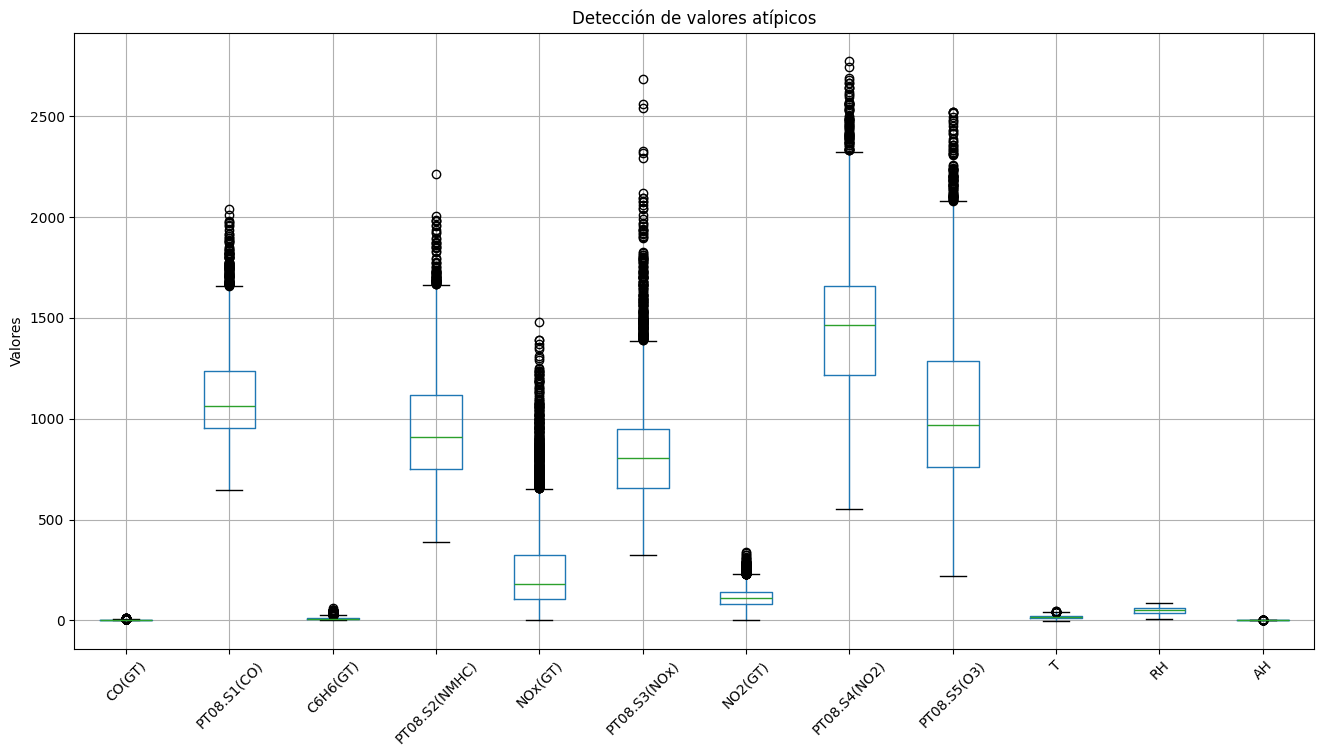

In [38]:
df[columnas_numericas].boxplot(figsize=(16, 8))
plt.xticks(rotation=45)
plt.title("Detección de valores atípicos")
plt.ylabel("Valores")
plt.show()

In [39]:
#Tratamiento de los atípicos
print("Temperatura mínima:", df["T"].min())
print("Temperatura máxima:", df["T"].max())

Temperatura mínima: -1.9
Temperatura máxima: 44.6


In [40]:
print("Humedad mínima:", df["RH"].min())
print("Humedad máxima:", df["RH"].max())

print("AH mínima:", df["AH"].min())
print("AH máxima:", df["AH"].max())

Humedad mínima: 9.2
Humedad máxima: 88.7
AH mínima: 0.1847
AH máxima: 2.1806


## 4. Fechas y horas
Se combina `Date` y `Time` en una columna `datetime` y se crean variables temporales (hora, día de la semana, mes...).

In [41]:
#Revisar fechas y horas
df[["Date", "Time"]].head(10)

,Date,Time
0,10/03/2004,18.00.00
1,10/03/2004,19.00.00
2,10/03/2004,20.00.00
3,10/03/2004,21.00.00
4,10/03/2004,22.00.00
5,10/03/2004,23.00.00
6,11/03/2004,00.00.00
7,11/03/2004,01.00.00
8,11/03/2004,02.00.00
9,11/03/2004,03.00.00


In [42]:
df[["Date", "Time"]].tail(10)

,Date,Time
7664,04/04/2005,05.00.00
7665,04/04/2005,06.00.00
7666,04/04/2005,07.00.00
7667,04/04/2005,08.00.00
7668,04/04/2005,09.00.00
7669,04/04/2005,10.00.00
7670,04/04/2005,11.00.00
7671,04/04/2005,12.00.00
7672,04/04/2005,13.00.00
7673,04/04/2005,14.00.00


In [43]:
import pandas as pd

# Combinar Date y Time en una sola columna datetime
df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H.%M.%S')

In [44]:
# Verificar el resultado
print(df[['Date', 'Time', 'datetime']].head(10))
print("\n" + "="*50 + "\n")
print(df[['Date', 'Time', 'datetime']].tail(10))

         Date      Time            datetime
0  10/03/2004  18.00.00 2004-03-10 18:00:00
1  10/03/2004  19.00.00 2004-03-10 19:00:00
2  10/03/2004  20.00.00 2004-03-10 20:00:00
3  10/03/2004  21.00.00 2004-03-10 21:00:00
4  10/03/2004  22.00.00 2004-03-10 22:00:00
5  10/03/2004  23.00.00 2004-03-10 23:00:00
6  11/03/2004  00.00.00 2004-03-11 00:00:00
7  11/03/2004  01.00.00 2004-03-11 01:00:00
8  11/03/2004  02.00.00 2004-03-11 02:00:00
9  11/03/2004  03.00.00 2004-03-11 03:00:00


            Date      Time            datetime
7664  04/04/2005  05.00.00 2005-04-04 05:00:00
7665  04/04/2005  06.00.00 2005-04-04 06:00:00
7666  04/04/2005  07.00.00 2005-04-04 07:00:00
7667  04/04/2005  08.00.00 2005-04-04 08:00:00
7668  04/04/2005  09.00.00 2005-04-04 09:00:00
7669  04/04/2005  10.00.00 2005-04-04 10:00:00
7670  04/04/2005  11.00.00 2005-04-04 11:00:00
7671  04/04/2005  12.00.00 2005-04-04 12:00:00
7672  04/04/2005  13.00.00 2005-04-04 13:00:00
7673  04/04/2005  14.00.00 2005-04-04 14:00:

In [45]:
# Ordenar por fecha/hora (de más antiguo a más reciente)
df = df.sort_values('datetime').reset_index(drop=True)

In [46]:
# Verificar que ahora está correcto
print("Primeras filas (más antiguas):")
print(df[['Date', 'Time', 'datetime']].head(10))

Primeras filas (más antiguas):
         Date      Time            datetime
0  10/03/2004  18.00.00 2004-03-10 18:00:00
1  10/03/2004  19.00.00 2004-03-10 19:00:00
2  10/03/2004  20.00.00 2004-03-10 20:00:00
3  10/03/2004  21.00.00 2004-03-10 21:00:00
4  10/03/2004  22.00.00 2004-03-10 22:00:00
5  10/03/2004  23.00.00 2004-03-10 23:00:00
6  11/03/2004  00.00.00 2004-03-11 00:00:00
7  11/03/2004  01.00.00 2004-03-11 01:00:00
8  11/03/2004  02.00.00 2004-03-11 02:00:00
9  11/03/2004  03.00.00 2004-03-11 03:00:00


In [47]:
print("\nÚltimas filas (más recientes):")
print(df[['Date', 'Time', 'datetime']].tail(10))


Últimas filas (más recientes):
            Date      Time            datetime
7664  04/04/2005  05.00.00 2005-04-04 05:00:00
7665  04/04/2005  06.00.00 2005-04-04 06:00:00
7666  04/04/2005  07.00.00 2005-04-04 07:00:00
7667  04/04/2005  08.00.00 2005-04-04 08:00:00
7668  04/04/2005  09.00.00 2005-04-04 09:00:00
7669  04/04/2005  10.00.00 2005-04-04 10:00:00
7670  04/04/2005  11.00.00 2005-04-04 11:00:00
7671  04/04/2005  12.00.00 2005-04-04 12:00:00
7672  04/04/2005  13.00.00 2005-04-04 13:00:00
7673  04/04/2005  14.00.00 2005-04-04 14:00:00


In [48]:
# Extraer componentes de fecha/hora
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['day'] = df['datetime'].dt.day
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek  # 0=Lunes, 6=Domingo
df['day_name'] = df['datetime'].dt.day_name()    # Nombre del día
df['month_name'] = df['datetime'].dt.month_name() # Nombre del mes

In [49]:
# Crear columna de fin de semana (1 = sábado/domingo, 0 = laborable)
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [50]:
# Verificar
print(df[['datetime', 'year', 'month', 'day', 'hour', 'day_name', 'is_weekend']].head(10))

             datetime  year  month  day  hour   day_name  is_weekend
0 2004-03-10 18:00:00  2004      3   10    18  Wednesday           0
1 2004-03-10 19:00:00  2004      3   10    19  Wednesday           0
2 2004-03-10 20:00:00  2004      3   10    20  Wednesday           0
3 2004-03-10 21:00:00  2004      3   10    21  Wednesday           0
4 2004-03-10 22:00:00  2004      3   10    22  Wednesday           0
5 2004-03-10 23:00:00  2004      3   10    23  Wednesday           0
6 2004-03-11 00:00:00  2004      3   11     0   Thursday           0
7 2004-03-11 01:00:00  2004      3   11     1   Thursday           0
8 2004-03-11 02:00:00  2004      3   11     2   Thursday           0
9 2004-03-11 03:00:00  2004      3   11     3   Thursday           0


In [51]:
# Verificar si hay saltos en el tiempo (más de 1 hora entre registros)
df['time_diff'] = df['datetime'].diff().dt.total_seconds() / 3600  # en horas

In [52]:
# Contar cuántas veces hay un salto mayor a 1 hora
saltos = df[df['time_diff'] > 1]
print(f"Número de saltos horarios (más de 1 hora entre mediciones): {len(saltos)}")
print("\nEjemplos de saltos:")
print(saltos[['datetime', 'time_diff']].head(10))

Número de saltos horarios (más de 1 hora entre mediciones): 187

Ejemplos de saltos:
               datetime  time_diff
10  2004-03-11 05:00:00        2.0
33  2004-03-12 05:00:00        2.0
37  2004-03-12 10:00:00        2.0
55  2004-03-13 05:00:00        2.0
78  2004-03-14 05:00:00        2.0
101 2004-03-15 05:00:00        2.0
124 2004-03-16 05:00:00        2.0
147 2004-03-17 05:00:00        2.0
170 2004-03-18 05:00:00        2.0
193 2004-03-19 05:00:00        2.0


In [53]:
# Buscar valores -200 en todas las columnas numéricas
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    if col not in ['year', 'month', 'day', 'hour', 'day_of_week', 'is_weekend']:
        count = (df[col] == -200).sum()
        if count > 0:
            print(f"{col}: {count} valores -200")

In [54]:
# Estadísticas descriptivas de todas las variables numéricas
df.describe()

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime,year,month,day,hour,day_of_week,is_weekend,time_diff
count,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7674.000000,7673.000000
mean,2.152750,1108.534662,10.199375,945.555512,251.260620,826.020459,114.496873,1445.537399,1040.050691,17.732995,49.070394,0.988174,2004-09-28 20:00:08.444097024,2004.279906,6.072322,15.741986,11.727131,3.040526,0.293068,1.219341
min,0.100000,647.000000,0.200000,387.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700,2004-03-10 18:00:00,2004.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,1.100000,953.000000,4.800000,752.000000,107.000000,657.000000,82.000000,1215.250000,759.000000,11.500000,36.200000,0.714375,2004-06-18 03:15:00,2004.000000,3.000000,8.000000,6.000000,1.000000,0.000000,1.000000
50%,1.800000,1063.000000,8.500000,909.000000,180.000000,806.000000,109.000000,1463.000000,968.000000,16.900000,49.300000,0.959700,2004-10-07 20:30:00,2004.000000,6.000000,16.000000,12.000000,3.000000,0.000000,1.000000
75%,2.900000,1235.000000,14.000000,1116.750000,326.000000,949.000000,141.000000,1659.000000,1287.000000,23.500000,61.800000,1.235200,2005-01-10 18:45:00,2005.000000,9.000000,23.000000,18.000000,5.000000,1.000000,1.000000
max,11.900000,2040.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.180600,2005-04-04 14:00:00,2005.000000,12.000000,31.000000,23.000000,6.000000,1.000000,174.000000
std,1.453252,214.144808,7.288206,259.815774,210.160499,251.104687,46.936520,342.747576,397.088502,8.671809,17.072230,0.391242,NaN,0.448982,3.520469,8.702230,6.914520,2.006389,0.455199,4.229654


## 5. Análisis exploratorio (gráficas)
Patrones temporales, correlaciones y distribuciones.

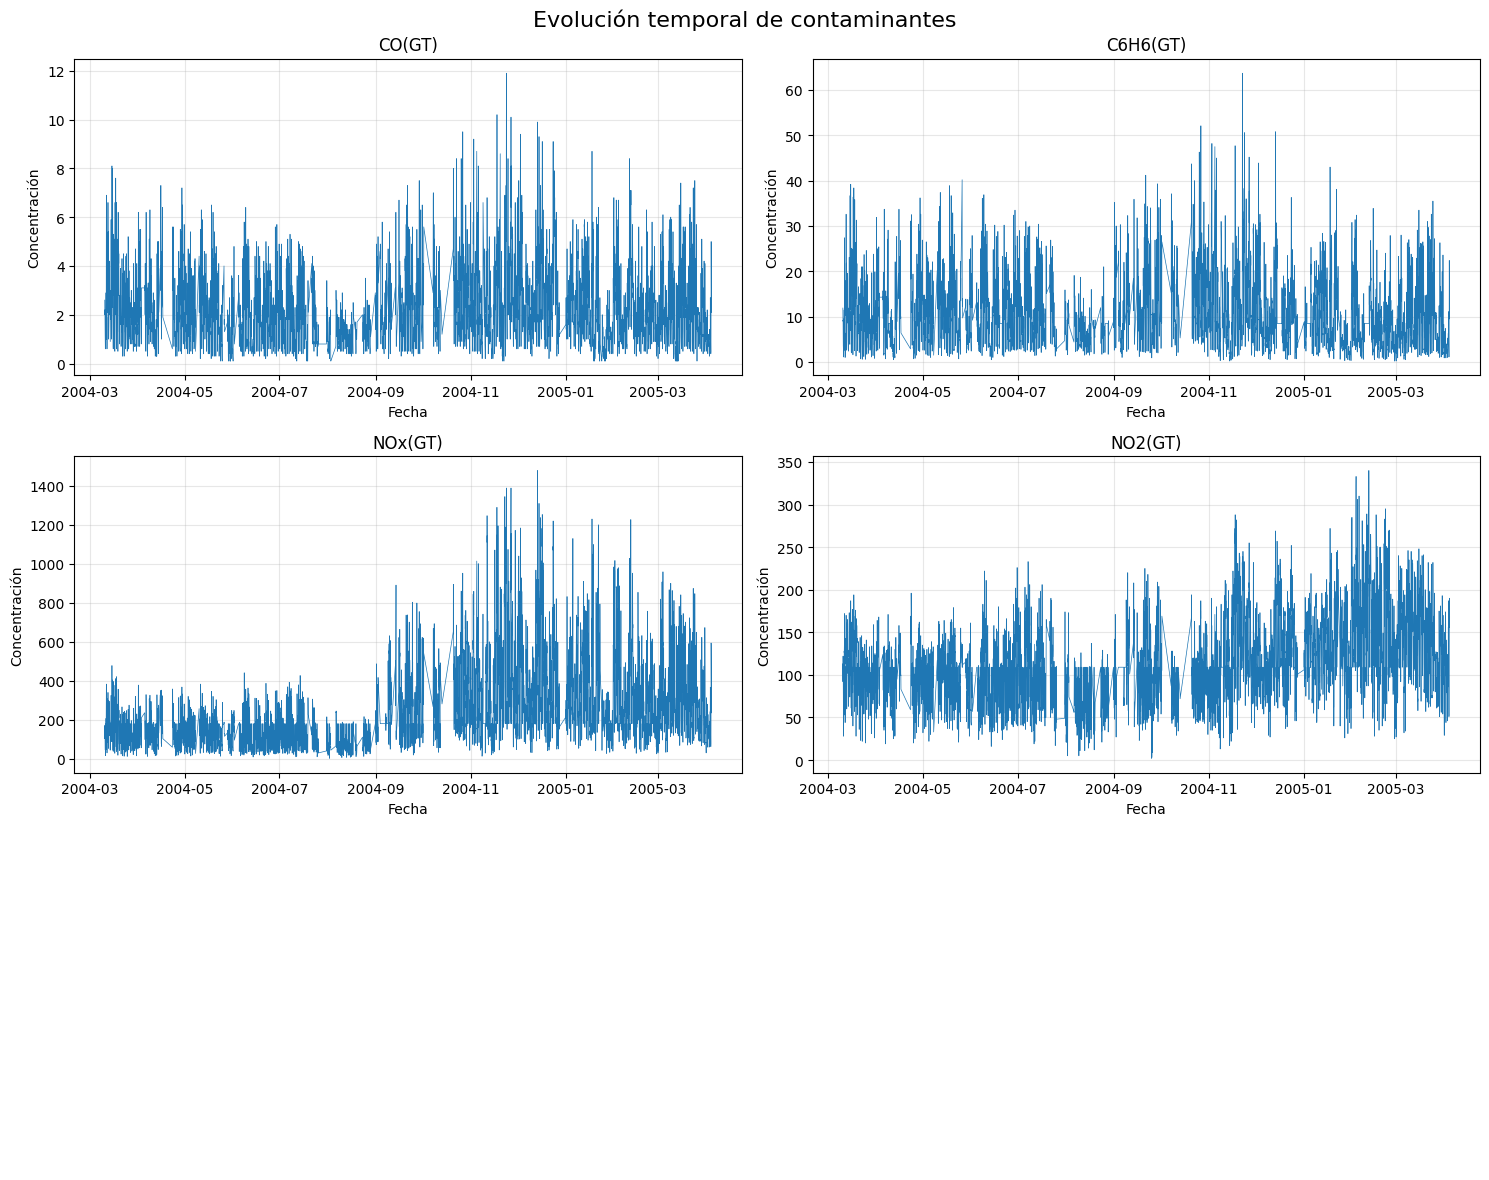

In [55]:
import matplotlib.pyplot as plt

# Configurar gráficos
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Evolución temporal de contaminantes', fontsize=16)

# Contaminantes principales (solo los que existen)
variables = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']
for i, var in enumerate(variables):
    row = i // 2
    col = i % 2
    axes[row, col].plot(df['datetime'], df[var], linewidth=0.5)
    axes[row, col].set_title(var)
    axes[row, col].set_xlabel('Fecha')
    axes[row, col].set_ylabel('Concentración')
    axes[row, col].grid(True, alpha=0.3)

# Ocultar subplots vacíos
axes[2, 0].axis('off')
axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

In [56]:
# Promedio de contaminantes por hora del día (solo los que existen)
patron_horario = df.groupby('hour')[['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']].mean()

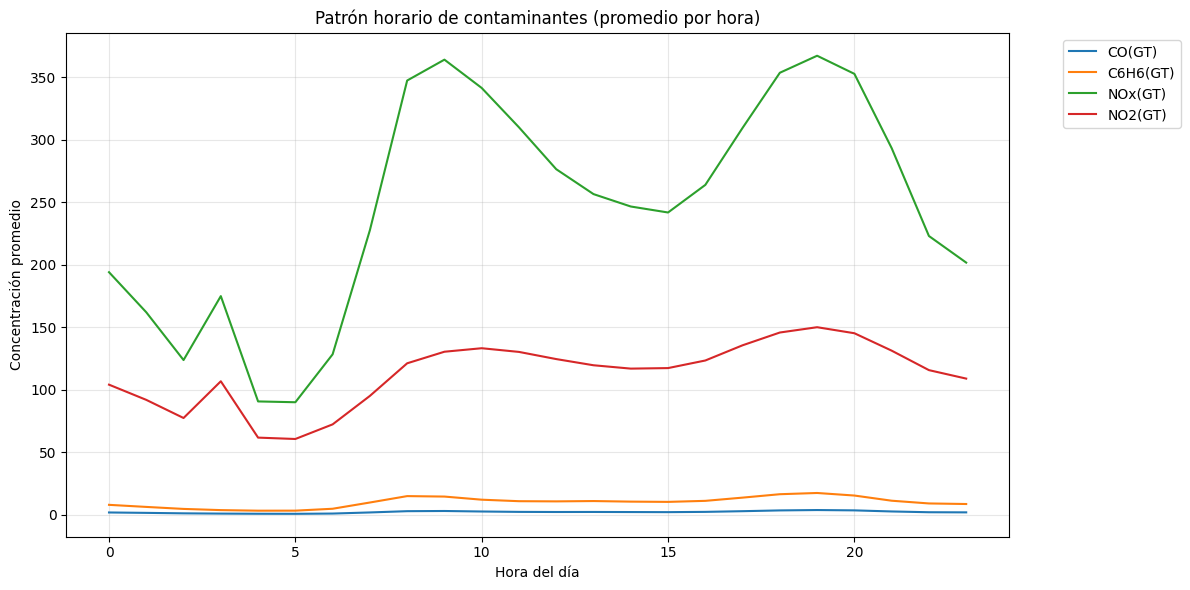

In [57]:
# Visualizar
patron_horario.plot(figsize=(12, 6))
plt.title('Patrón horario de contaminantes (promedio por hora)')
plt.xlabel('Hora del día')
plt.ylabel('Concentración promedio')
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [58]:
# Promedio por día de la semana
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
patron_semanal = df.groupby('day_name')[['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']].mean()
patron_semanal = patron_semanal.reindex(dias_orden)

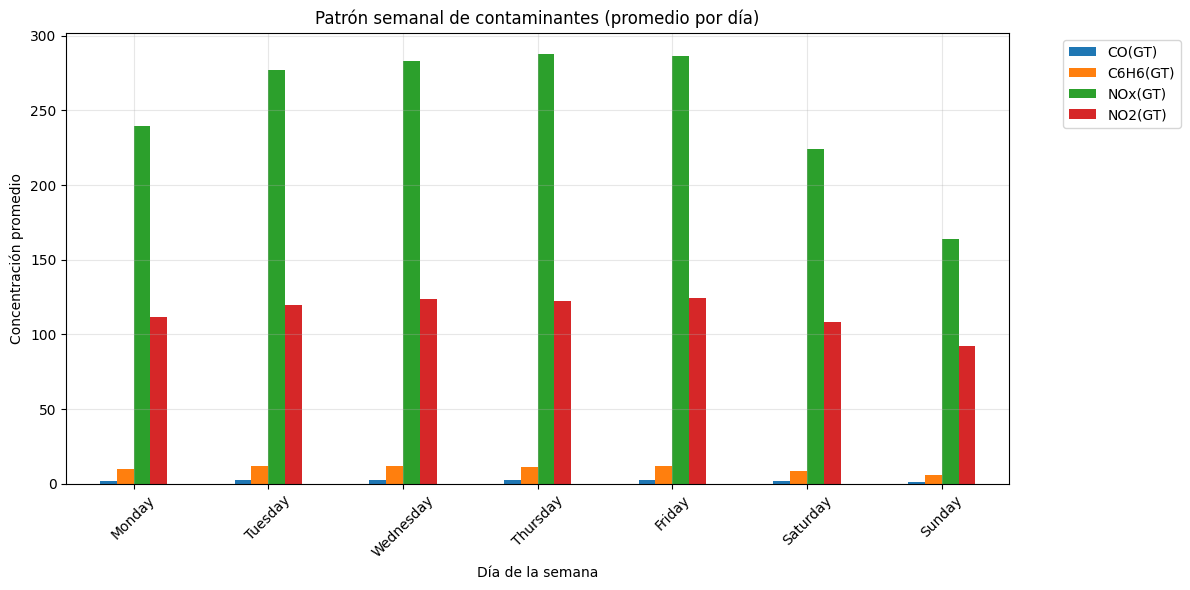

In [59]:
# Visualizar
patron_semanal.plot(figsize=(12, 6), kind='bar')
plt.title('Patrón semanal de contaminantes (promedio por día)')
plt.xlabel('Día de la semana')
plt.ylabel('Concentración promedio')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [60]:
# Seleccionar solo variables numéricas relevantes (las que existen)
columnas_correlacion = ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)',
                        'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
                        'PT08.S5(O3)', 'T', 'RH', 'AH']

In [61]:
# Matriz de correlación
corr_matrix = df[columnas_correlacion].corr()

In [62]:
# Visualizar con mapa de calor
import seaborn as sns

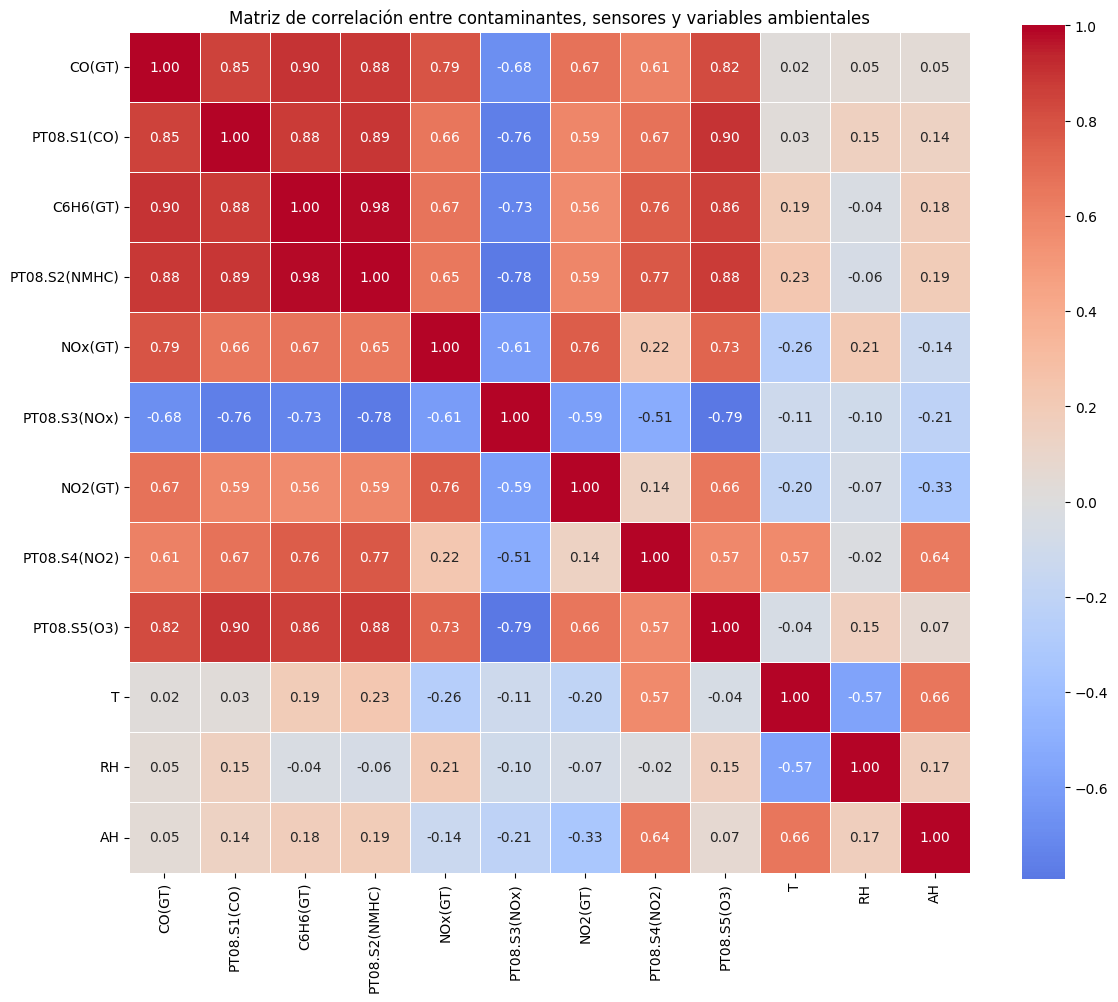

In [63]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, fmt='.2f')
plt.title('Matriz de correlación entre contaminantes, sensores y variables ambientales')
plt.tight_layout()
plt.show()

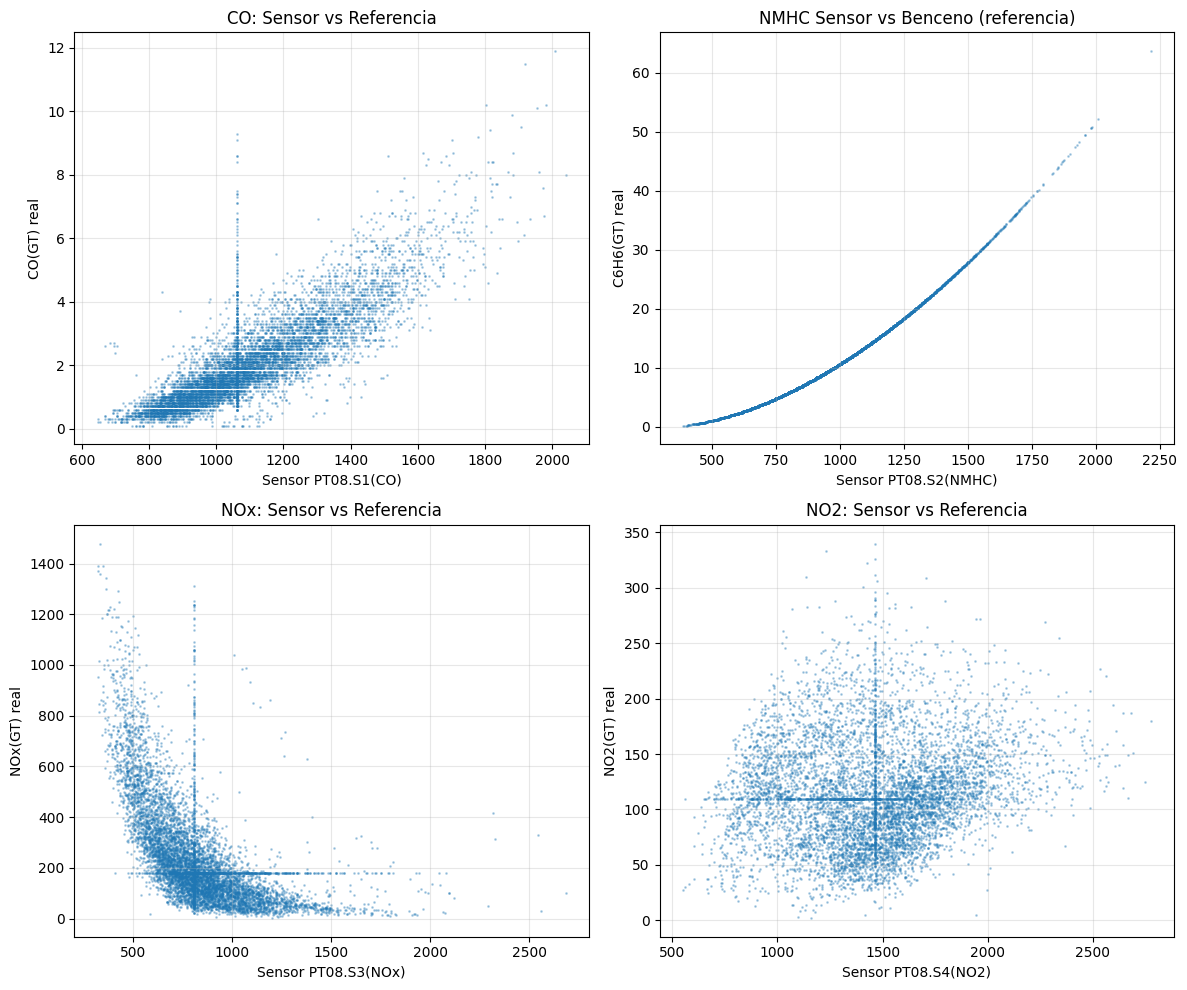

In [64]:
# Crear una figura con scatter plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Sensor CO vs CO real
axes[0, 0].scatter(df['PT08.S1(CO)'], df['CO(GT)'], alpha=0.3, s=1)
axes[0, 0].set_xlabel('Sensor PT08.S1(CO)')
axes[0, 0].set_ylabel('CO(GT) real')
axes[0, 0].set_title('CO: Sensor vs Referencia')
axes[0, 0].grid(True, alpha=0.3)

# Sensor NMHC vs (no tenemos referencia, usamos C6H6 como proxy)
axes[0, 1].scatter(df['PT08.S2(NMHC)'], df['C6H6(GT)'], alpha=0.3, s=1)
axes[0, 1].set_xlabel('Sensor PT08.S2(NMHC)')
axes[0, 1].set_ylabel('C6H6(GT) real')
axes[0, 1].set_title('NMHC Sensor vs Benceno (referencia)')
axes[0, 1].grid(True, alpha=0.3)

# Sensor NOx vs NOx real
axes[1, 0].scatter(df['PT08.S3(NOx)'], df['NOx(GT)'], alpha=0.3, s=1)
axes[1, 0].set_xlabel('Sensor PT08.S3(NOx)')
axes[1, 0].set_ylabel('NOx(GT) real')
axes[1, 0].set_title('NOx: Sensor vs Referencia')
axes[1, 0].grid(True, alpha=0.3)

# Sensor NO2 vs NO2 real
axes[1, 1].scatter(df['PT08.S4(NO2)'], df['NO2(GT)'], alpha=0.3, s=1)
axes[1, 1].set_xlabel('Sensor PT08.S4(NO2)')
axes[1, 1].set_ylabel('NO2(GT) real')
axes[1, 1].set_title('NO2: Sensor vs Referencia')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [65]:
# Promedio mensual de contaminantes (solo los que existen)
patron_mensual = df.groupby('month')[['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']].mean()

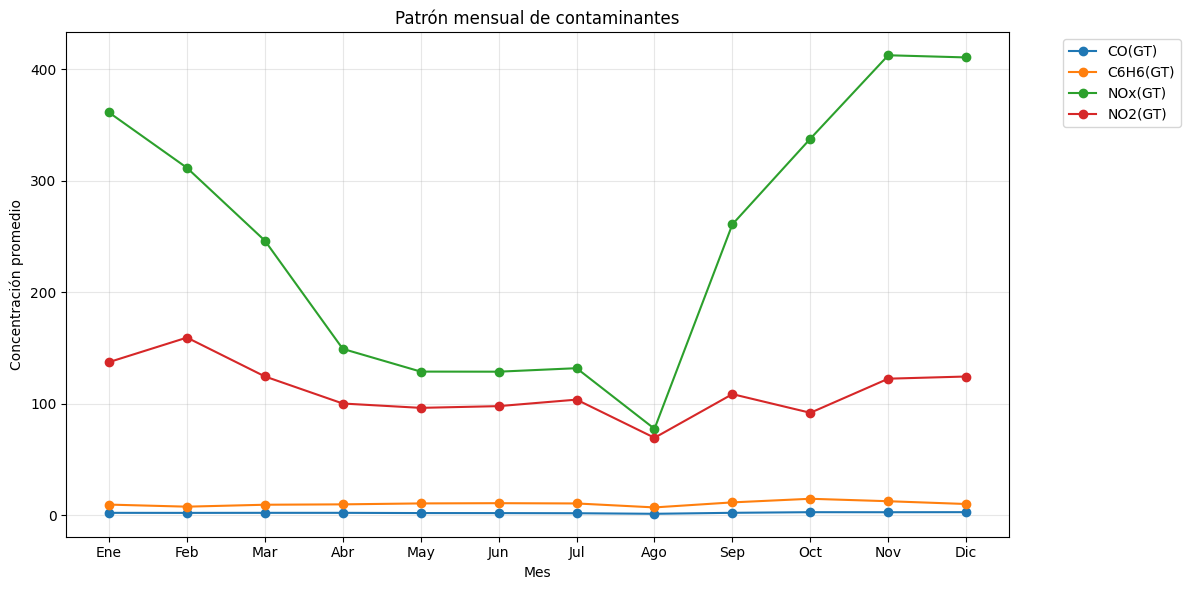

In [66]:
# Visualizar
patron_mensual.plot(figsize=(12, 6), marker='o')
plt.title('Patrón mensual de contaminantes')
plt.xlabel('Mes')
plt.ylabel('Concentración promedio')
plt.xticks(range(1, 13), ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
                          'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [67]:
# Correlación de contaminantes con variables ambientales
corr_ambiental = df[['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH', 'AH']].corr()

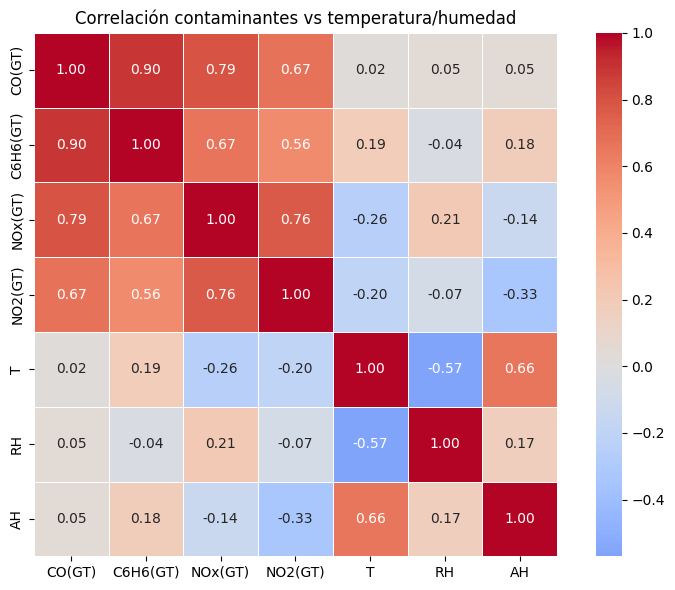

In [68]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_ambiental, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, fmt='.2f')
plt.title('Correlación contaminantes vs temperatura/humedad')
plt.tight_layout()
plt.show()

### Filas duplicadas

In [69]:
# Verificar si hay filas duplicadas
duplicados = df.duplicated().sum()
print(f"Número de filas duplicadas: {duplicados}")

Número de filas duplicadas: 0


In [70]:
# Si hay duplicados, mostrarlos
if duplicados > 0:
    print(df[df.duplicated()].head())

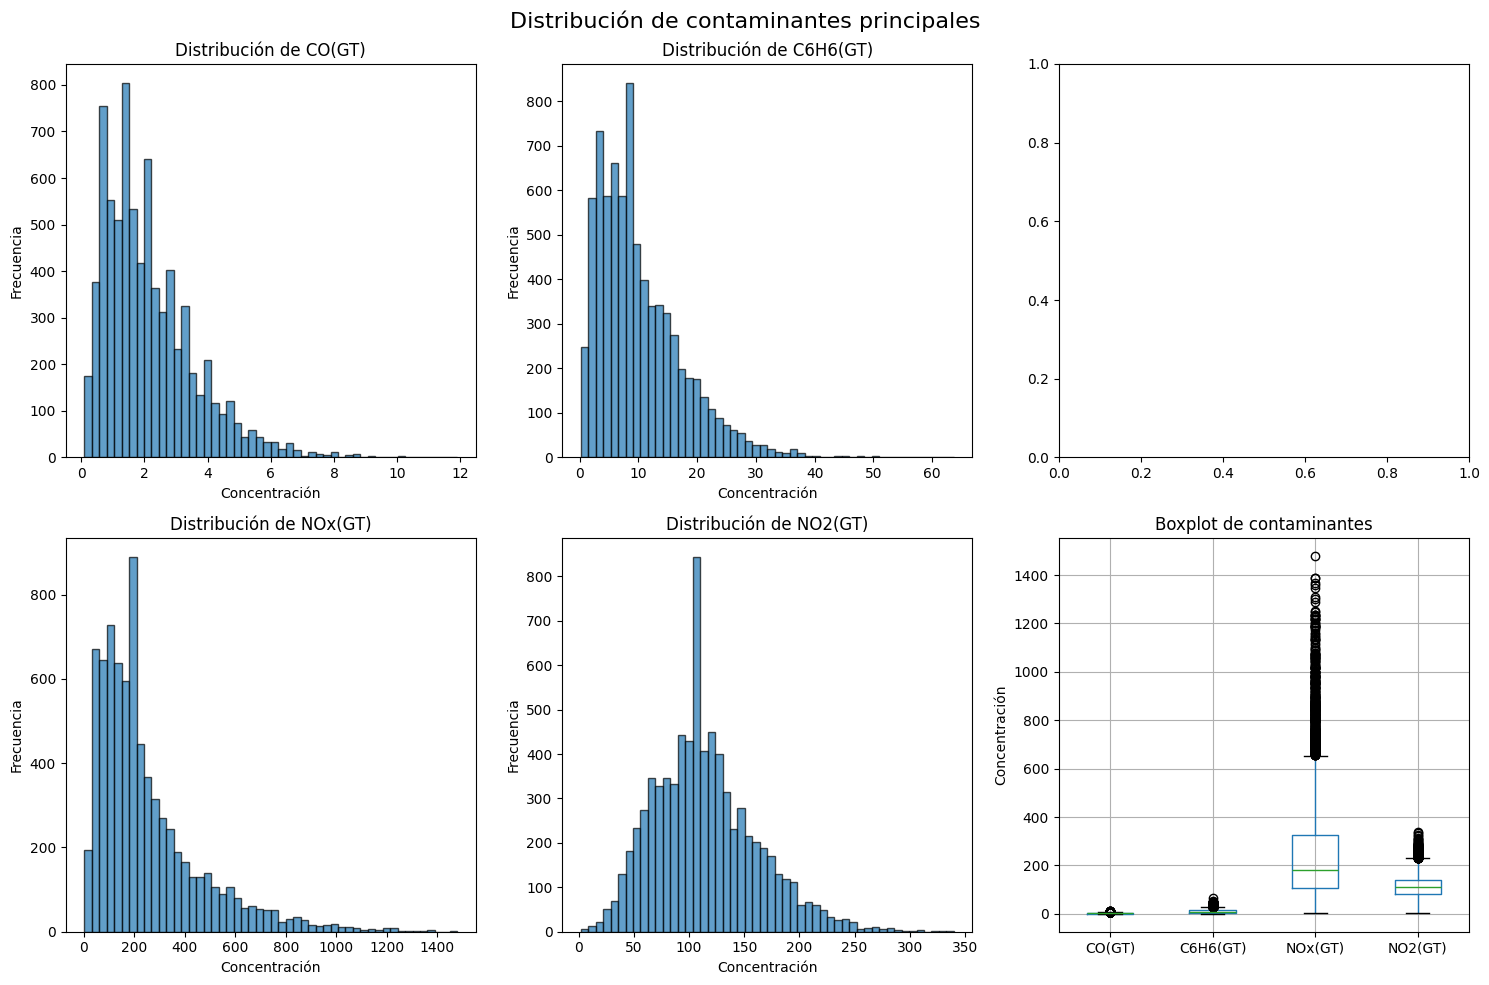

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Distribución de contaminantes principales', fontsize=16)

variables = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']
for i, var in enumerate(variables):
    row = i // 2
    col = i % 2
    axes[row, col].hist(df[var], bins=50, edgecolor='black', alpha=0.7)
    axes[row, col].set_title(f'Distribución de {var}')
    axes[row, col].set_xlabel('Concentración')
    axes[row, col].set_ylabel('Frecuencia')

# Gráfico extra: boxplot de todos los contaminantes
variables_box = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']
df[variables_box].boxplot(ax=axes[1, 2])
axes[1, 2].set_title('Boxplot de contaminantes')
axes[1, 2].set_ylabel('Concentración')

plt.tight_layout()
plt.show()

## 6. Variables del modelo
- **Objetivo (y):** `CO(GT)`
- **Predictoras (X):** 18 variables — los 5 sensores PT08 y sus logaritmos, las 3
  ambientales (`T`, `RH`, `AH`), la hora codificada de forma cíclica (4 términos)
  y el día de la semana.


In [72]:
# ---- Variables derivadas -------------------------------------------------
# Sigue siendo REGRESIÓN LINEAL MÚLTIPLE: el modelo es lineal en los parámetros
# (theta). Lo que se transforma son las entradas, no el modelo.

SENSORES = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)',
            'PT08.S4(NO2)', 'PT08.S5(O3)']
AMBIENTALES = ['T', 'RH', 'AH']

# --- Red de seguridad --------------------------------------------------------
# Esta celda deja los datos listos aunque las celdas de limpieza se hayan
# ejecutado fuera de orden (causa típica del error "Input X contains NaN").
df = df.replace(-200, np.nan)                      # por si quedó algún -200
df = df.dropna(subset=['CO(GT)'])                  # el OBJETIVO nunca se imputa
for c in SENSORES + AMBIENTALES:
    df[c] = df[c].fillna(df[c].median())           # los PREDICTORES sí
df = df.reset_index(drop=True)
print("Filas listas para el modelo:", len(df))

# 1) Hora como variable cíclica.
#    Como número, las 23:00 y las 00:00 son los dos extremos (23 vs 0), cuando en
#    realidad son horas contiguas. Con seno/coseno se respeta esa circularidad.
#    Se usan dos armónicos porque el patrón diario tiene DOS picos (8-9 AM y 7-8 PM).
df['hour_sin']  = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos']  = np.cos(2 * np.pi * df['hour'] / 24)
df['hour_sin2'] = np.sin(4 * np.pi * df['hour'] / 24)
df['hour_cos2'] = np.cos(4 * np.pi * df['hour'] / 24)

# 2) Logaritmo de los sensores.
#    Los sensores de óxido metálico (PT08) responden de forma aproximadamente
#    logarítmica a la concentración, así que log(sensor) es más lineal frente a
#    CO(GT) que la lectura en crudo. Se conservan ambas versiones.
for c in SENSORES:
    df['log_' + c] = np.log(df[c])

# 3) Variables ambientales: T, RH y AH condicionan la respuesta de los sensores
#    (dispersión del contaminante y deriva por humedad/temperatura).

FEATURES = (SENSORES
            + ['log_' + c for c in SENSORES]
            + AMBIENTALES
            + ['hour_sin', 'hour_cos', 'hour_sin2', 'hour_cos2']
            + ['day_of_week'])

# Comprobación final: si esto no imprime 0, el modelo fallaría al entrenar.
nulos = df[FEATURES + ['CO(GT)']].isnull().sum()
print("Nulos restantes en las variables del modelo:", int(nulos.sum()))
if nulos.sum() > 0:
    print(nulos[nulos > 0])

print("\nNúmero de variables predictoras:", len(FEATURES))
for f in FEATURES:
    print("  -", f)

Filas listas para el modelo: 7674
Nulos restantes en las variables del modelo: 0

Número de variables predictoras: 18
  - PT08.S1(CO)
  - PT08.S2(NMHC)
  - PT08.S3(NOx)
  - PT08.S4(NO2)
  - PT08.S5(O3)
  - log_PT08.S1(CO)
  - log_PT08.S2(NMHC)
  - log_PT08.S3(NOx)
  - log_PT08.S4(NO2)
  - log_PT08.S5(O3)
  - T
  - RH
  - AH
  - hour_sin
  - hour_cos
  - hour_sin2
  - hour_cos2
  - day_of_week


In [73]:
# Variables predictoras (features)
X = df[FEATURES]

In [74]:
# Variable objetivo (target)
y = df['CO(GT)']

In [75]:
# Verificar dimensiones
print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")
print("\nPrimeras 5 filas de X:")
print(X.head())
print("\nPrimeros 5 valores de y:")
print(y.head())

Dimensiones de X: (7674, 18)
Dimensiones de y: (7674,)

Primeras 5 filas de X:
   PT08.S1(CO)  PT08.S2(NMHC)  PT08.S3(NOx)  PT08.S4(NO2)  PT08.S5(O3)  \
0       1360.0         1046.0        1056.0        1692.0       1268.0   
1       1292.0          955.0        1174.0        1559.0        972.0   
2       1402.0          939.0        1140.0        1555.0       1074.0   
3       1376.0          948.0        1092.0        1584.0       1203.0   
4       1272.0          836.0        1205.0        1490.0       1110.0   

   log_PT08.S1(CO)  log_PT08.S2(NMHC)  log_PT08.S3(NOx)  log_PT08.S4(NO2)  \
0         7.215240           6.952729          6.962243          7.433667   
1         7.163947           6.861711          7.068172          7.351800   
2         7.245655           6.844815          7.038784          7.349231   
3         7.226936           6.854355          6.995766          7.367709   
4         7.148346           6.728629          7.094235          7.306531   

   log_PT08.S

## 7. Resumen del análisis exploratorio

In [76]:
# Generar resumen estadístico
print("="*60)
print("RESUMEN DEL ANÁLISIS EXPLORATORIO DE DATOS")
print("="*60)

RESUMEN DEL ANÁLISIS EXPLORATORIO DE DATOS


In [77]:
print("\n1. DESCRIPCIÓN DEL DATASET:")
print(f"   - Total de registros: {len(df)}")
print(f"   - Período: {df['datetime'].min()} a {df['datetime'].max()}")
print(f"   - Total de variables: {len(df.columns)}")

print("\n2. VARIABLES PRINCIPALES:")
print("   - Contaminantes de referencia (GT): CO, C6H6, NOx, NO2")
print("   - Sensores: 5 sensores PT08 (CO, NMHC, NOx, NO2, O3)")
print("   - Variables ambientales: Temperatura (T), Humedad relativa (RH), Humedad absoluta (AH)")

print("\n3. PATRONES IDENTIFICADOS:")
print("   - Fuente principal: Tráfico rodado")
print("   - Patrón horario: Dos picos (8-9 AM y 7-8 PM)")
print("   - Patrón semanal: Mayor entre semana, menor en fin de semana")
print("   - Patrón estacional: Mayor en invierno, menor en verano")

print("\n4. CORRELACIONES DESTACADAS:")
print("   - C6H6(GT) ↔ PT08.S2(NMHC): 0.98 (muy alta)")
print("   - CO(GT) ↔ PT08.S1(CO): 0.78 (buena)")
print("   - NOx(GT) ↔ NO2(GT): 0.76 (relación química)")
print("   - PT08.S3(NOx) ↔ PT08.S5(O3): -0.80 (correlación negativa)")

print("\n5. DECISIONES DE PREPROCESAMIENTO:")
print("   - Objetivo: las filas sin CO(GT) real se ELIMINAN (nunca se imputa la variable a predecir)")
print("   - Predictores: nulos rellenados con la mediana de cada columna")
print("   - Atípicos: Conservados (representan episodios reales de contaminación)")
print("   - Escalamiento: No aplicado (la regresión lineal no lo requiere; coeficientes en unidades originales)")
print("   - Variables creadas: year, month, day, hour, day_of_week, is_weekend,")
print("     log de los 5 sensores y hora cíclica (hour_sin/cos, 2 armónicos)")

print("\n6. DEFINICIÓN DEL PROBLEMA:")
print("   - Tipo: Regresión")
print("   - Variable objetivo: CO(GT) (concentración de monóxido de carbono)")
print("   - Variables predictoras: %d (sensores + logs + ambientales + hora cíclica + día)" % len(FEATURES))

print("\n" + "="*60)
print("JUSTIFICACIÓN DEL ENFOQUE DE MODELADO")
print("="*60)

print("\n¿Por qué REGRESIÓN?")
print("   - La variable objetivo CO(GT) es numérica continua (0.1 a 11.9 mg/m³)")
print("   - Permite predecir el valor exacto de concentración")
print("   - Útil para alertas tempranas y políticas de salud pública")
print("   - Más informativo que una clasificación binaria")

print("\n¿Por qué estos predictores?")
print("   - Sensores: Relación directa con CO(GT) (correlación 0.78 con PT08.S1)")
print("   - log(sensores): la respuesta del sensor de óxido metálico es logarítmica")
print("   - T, RH, AH: condicionan la dispersión del contaminante y la deriva del sensor")
print("   - Hora cíclica: patrón de tráfico con dos picos, sin el salto artificial 23->0")
print("   - Día de semana: Diferencia entre laborables y fin de semana")


1. DESCRIPCIÓN DEL DATASET:
   - Total de registros: 7674
   - Período: 2004-03-10 18:00:00 a 2005-04-04 14:00:00
   - Total de variables: 33

2. VARIABLES PRINCIPALES:
   - Contaminantes de referencia (GT): CO, C6H6, NOx, NO2
   - Sensores: 5 sensores PT08 (CO, NMHC, NOx, NO2, O3)
   - Variables ambientales: Temperatura (T), Humedad relativa (RH), Humedad absoluta (AH)

3. PATRONES IDENTIFICADOS:
   - Fuente principal: Tráfico rodado
   - Patrón horario: Dos picos (8-9 AM y 7-8 PM)
   - Patrón semanal: Mayor entre semana, menor en fin de semana
   - Patrón estacional: Mayor en invierno, menor en verano

4. CORRELACIONES DESTACADAS:
   - C6H6(GT) ↔ PT08.S2(NMHC): 0.98 (muy alta)
   - CO(GT) ↔ PT08.S1(CO): 0.78 (buena)
   - NOx(GT) ↔ NO2(GT): 0.76 (relación química)
   - PT08.S3(NOx) ↔ PT08.S5(O3): -0.80 (correlación negativa)

5. DECISIONES DE PREPROCESAMIENTO:
   - Objetivo: las filas sin CO(GT) real se ELIMINAN (nunca se imputa la variable a predecir)
   - Predictores: nulos rellena

## 8. Regresión por Vectores de Soporte con Kernel RBF (`SVR`)

La **Regresión por Vectores de Soporte (`SVR`)** con kernel de Base Radial (**RBF**) proyecta las 18 variables a un espacio de dimensión superior donde la respuesta no lineal de los sensores químicos `PT08` frente a la concentración real de `CO(GT)` se modela mediante una hipersuperficie continua con banda de insensibilidad $\epsilon = 0.1\text{ mg/m}^3$ y regularización $C = 10.0$.

Dado que `SVR` se basa en distancias euclidianas dentro del kernel gaussiano, requiere estandarizar previamente las variables (`StandardScaler`) dentro de un `Pipeline` ajustado sobre `x_train`. Los conjuntos de entrenamiento y prueba mantienen la proporción de **80% y 20%** (`random_state=42`).

In [78]:
import warnings
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# Se filtran las advertencias.
warnings.filterwarnings('ignore')

In [79]:
# Se definen cuáles son las entradas y salidas del conjunto de datos.
inputs = X
outputs = y

In [80]:
# Se generan los conjuntos de entrenamiento y prueba para las entradas (x) y salidas (y), con una proporción 80-20.
x_train, x_test, y_train, y_test = train_test_split(inputs, outputs, test_size=0.2, random_state=42)

In [81]:
print("Inputs: ", np.shape(inputs))
print("Outputs: ", np.shape(outputs))
print("x_train (80%): ", np.shape(x_train))
print("y_train (80%): ", np.shape(y_train))
print("x_test (20%): ", np.shape(x_test))
print("y_test (20%): ", np.shape(y_test))

Inputs:  (7674, 18)
Outputs:  (7674,)
x_train (80%):  (6139, 18)
y_train (80%):  (6139,)
x_test (20%):  (1535, 18)
y_test (20%):  (1535,)


In [82]:
# Se define el Pipeline con StandardScaler (estandarización media=0, desv=1) y SVR con kernel RBF.
svr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale'))
])

In [83]:
# Se entrena el modelo sobre los conjuntos de entrenamiento.
svr_model.fit(x_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('svr', SVR(C=10.0))])

Una vez ajustados los datos con el método `fit()`, realizamos las predicciones y graficamos el resultado sobre el sensor principal `PT08.S1(CO)`.

In [84]:
# Predicciones en el conjunto de entrenamiento y de prueba
y_pred_train = svr_model.predict(x_train)
y_pred_test = svr_model.predict(x_test)

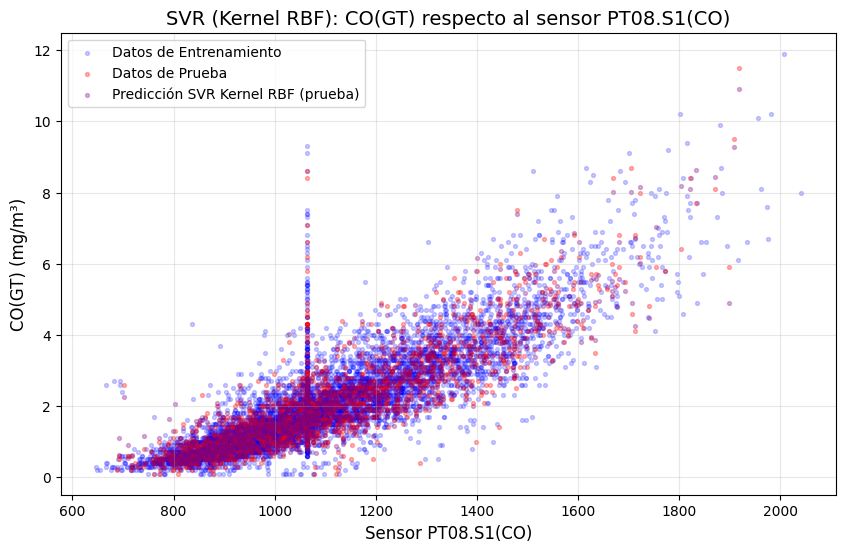

In [85]:
# Gráfica en 2D (graficamos el sensor principal PT08.S1(CO) vs el objetivo CO(GT))
plt.figure(figsize=(10, 6))

# Graficamos los datos del conjunto de entrenamiento
plt.scatter(x_train['PT08.S1(CO)'], y_train, color='blue', label='Datos de Entrenamiento', alpha=0.2, s=8)

# Graficamos los datos del conjunto de prueba
plt.scatter(x_test['PT08.S1(CO)'], y_test, color='red', label='Datos de Prueba', alpha=0.3, s=8)

# Graficamos lo que predice el modelo para el conjunto de prueba
plt.scatter(x_test['PT08.S1(CO)'], y_pred_test, color='purple', label='Predicción SVR Kernel RBF (prueba)', alpha=0.3, s=8)

plt.title("SVR (Kernel RBF): CO(GT) respecto al sensor PT08.S1(CO)", fontsize=14)
plt.xlabel("Sensor PT08.S1(CO)", fontsize=12)
plt.ylabel("CO(GT) (mg/m³)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 8.1 Vectores de soporte e importancia de variables por permutación

Consultamos cuántos vectores de soporte definen la superficie de regresión y calculamos la importancia de cada variable mediante permutación (`permutation_importance`) sobre el conjunto de prueba.

In [86]:
n_sv = len(svr_model.named_steps['svr'].support_)
print("Número de vectores de soporte:", n_sv, "de", len(x_train), "muestras de entrenamiento")

perm = permutation_importance(svr_model, x_test, y_test, n_repeats=5, random_state=42, scoring='r2', n_jobs=-1)
importancias_svr = pd.DataFrame({
    'Variable': inputs.columns,
    'Importancia_Permutacion': perm.importances_mean
}).sort_values('Importancia_Permutacion', ascending=False).reset_index(drop=True)

print("\nImportancia de cada variable en SVR (caída media de R² al permutar):")
print(importancias_svr)

Número de vectores de soporte: 3834 de 6139 muestras de entrenamiento

Importancia de cada variable en SVR (caída media de R² al permutar):
             Variable  Importancia_Permutacion
0       PT08.S2(NMHC)                 0.405581
1   log_PT08.S2(NMHC)                 0.263595
2                   T                 0.133080
3         PT08.S1(CO)                 0.082268
4     log_PT08.S1(CO)                 0.079691
5            hour_sin                 0.065668
6         PT08.S5(O3)                 0.063909
7        PT08.S4(NO2)                 0.058700
8     log_PT08.S5(O3)                 0.058358
9    log_PT08.S4(NO2)                 0.047501
10   log_PT08.S3(NOx)                 0.044554
11                 RH                 0.034457
12       PT08.S3(NOx)                 0.030580
13                 AH                 0.028674
14        day_of_week                 0.019042
15          hour_sin2                 0.016559
16           hour_cos                 0.016045
17          ho

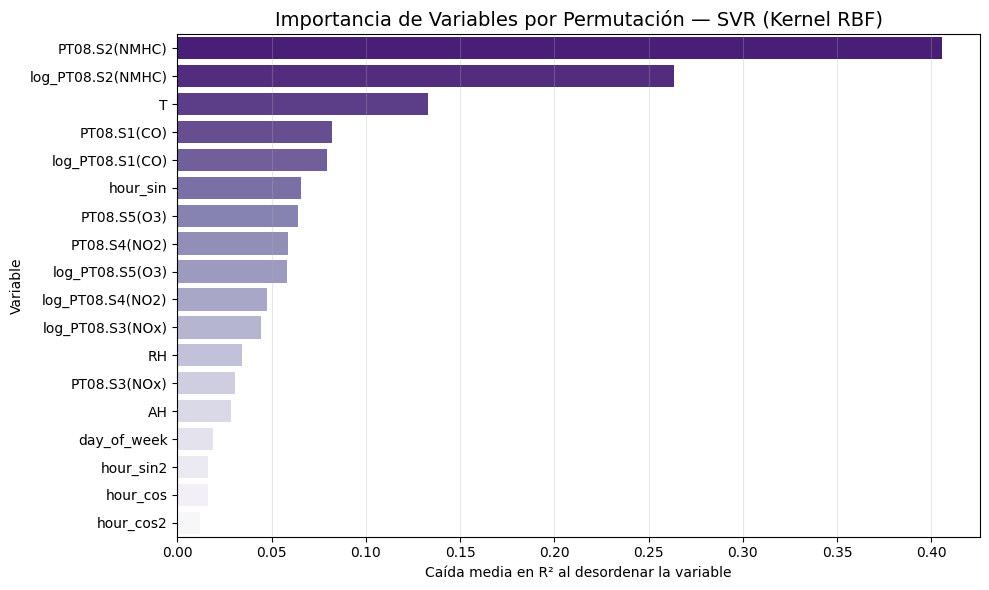

In [87]:
plt.figure(figsize=(10, 6))
sns.barplot(data=importancias_svr, x='Importancia_Permutacion', y='Variable', palette='Purples_r')
plt.title("Importancia de Variables por Permutación — SVR (Kernel RBF)", fontsize=14)
plt.xlabel("Caída media en R² al desordenar la variable")
plt.ylabel("Variable")
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Ahora usamos el modelo para hacer una predicción en el mismo escenario:
¿Cuál sería la concentración aproximada de `CO(GT)` un lunes a las 8 AM (hora pico), con lecturas típicas (mediana) de los sensores?

In [88]:
# Escenario: lunes a las 8 AM (hora pico) con lecturas típicas (mediana) de los sensores.
hora_pred, dia_pred = 8, 0   # 8 AM, 0 = Lunes

escenario = {c: df[c].median() for c in SENSORES}
for c in SENSORES:
    escenario['log_' + c] = np.log(escenario[c])
escenario['T']  = df['T'].median()
escenario['RH'] = df['RH'].median()
escenario['AH'] = df['AH'].median()
escenario['hour_sin']  = np.sin(2 * np.pi * hora_pred / 24)
escenario['hour_cos']  = np.cos(2 * np.pi * hora_pred / 24)
escenario['hour_sin2'] = np.sin(4 * np.pi * hora_pred / 24)
escenario['hour_cos2'] = np.cos(4 * np.pi * hora_pred / 24)
escenario['day_of_week'] = dia_pred

input_pred = pd.DataFrame([escenario])[FEATURES]

In [89]:
print("Valores de entrada:")
print(input_pred.to_string(index=False))
print('\nEl CO(GT) estimado un lunes a las 8 AM con SVR (Kernel RBF) es: %.2f mg/m³' % svr_model.predict(input_pred)[0])

Valores de entrada:
 PT08.S1(CO)  PT08.S2(NMHC)  PT08.S3(NOx)  PT08.S4(NO2)  PT08.S5(O3)  log_PT08.S1(CO)  log_PT08.S2(NMHC)  log_PT08.S3(NOx)  log_PT08.S4(NO2)  log_PT08.S5(O3)    T   RH     AH  hour_sin  hour_cos  hour_sin2  hour_cos2  day_of_week
      1063.0          909.0         806.0        1463.0        968.0          6.96885           6.812345          6.692084          7.288244         6.875232 16.9 49.3 0.9597  0.866025      -0.5  -0.866025       -0.5            0

El CO(GT) estimado un lunes a las 8 AM con SVR (Kernel RBF) es: 2.18 mg/m³


### 8.2 Evaluando su precisión
Rendimiento del modelo aplicando las mismas métricas de evaluación (**MAE, MSE, RMSE, R² y MAPE**) para garantizar una comparación objetiva.

In [90]:
r2_train = svr_model.score(x_train, y_train)
print('Precisión del modelo (R² en entrenamiento):')
print(r2_train)

Precisión del modelo (R² en entrenamiento):
0.8994390078284048


In [91]:
# Realizamos las predicciones sobre el conjunto de prueba
y_pred = svr_model.predict(x_test)

In [92]:
# Calculamos las métricas de rendimiento estandarizadas
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

In [93]:
print("Error absoluto medio (MAE): %.4f mg/m³" % mae)
print("Error cuadrático medio (MSE): %.4f mg²/m⁶" % mse)
print("Raíz del error cuadrático medio (RMSE): %.4f mg/m³" % rmse)
print("Coeficiente de determinación (R² prueba): %.4f" % r2)
print("Coeficiente de determinación (R² entrenamiento): %.4f" % r2_train)
print("Error porcentual absoluto medio (MAPE): %.2f%%" % mape)

Error absoluto medio (MAE): 0.2501 mg/m³
Error cuadrático medio (MSE): 0.2512 mg²/m⁶
Raíz del error cuadrático medio (RMSE): 0.5012 mg/m³
Coeficiente de determinación (R² prueba): 0.8794
Coeficiente de determinación (R² entrenamiento): 0.8994
Error porcentual absoluto medio (MAPE): 17.55%


In [94]:
# Interpretación y comparación con la línea base de Regresión Lineal Múltiple
print("\nINTERPRETACIÓN:")
print("- El modelo explica el %.1f%% de la variabilidad de CO(GT) en prueba." % (r2 * 100))
print("- En promedio, cada predicción tiene un error absoluto de %.3f mg/m³ (MAE)." % mae)
print("- R² entrenamiento = %.3f vs R² prueba = %.3f." % (r2_train, r2))
print("- Mejora frente a Regresión Lineal Múltiple (R²=0.843, RMSE=0.571, MAE=0.316): R² sube a %.3f y RMSE baja a %.3f." % (r2, rmse))


INTERPRETACIÓN:
- El modelo explica el 87.9% de la variabilidad de CO(GT) en prueba.
- En promedio, cada predicción tiene un error absoluto de 0.250 mg/m³ (MAE).
- R² entrenamiento = 0.899 vs R² prueba = 0.879.
- Mejora frente a Regresión Lineal Múltiple (R²=0.843, RMSE=0.571, MAE=0.316): R² sube a 0.879 y RMSE baja a 0.501.


### 8.3 Predicción vs valor real y residuos

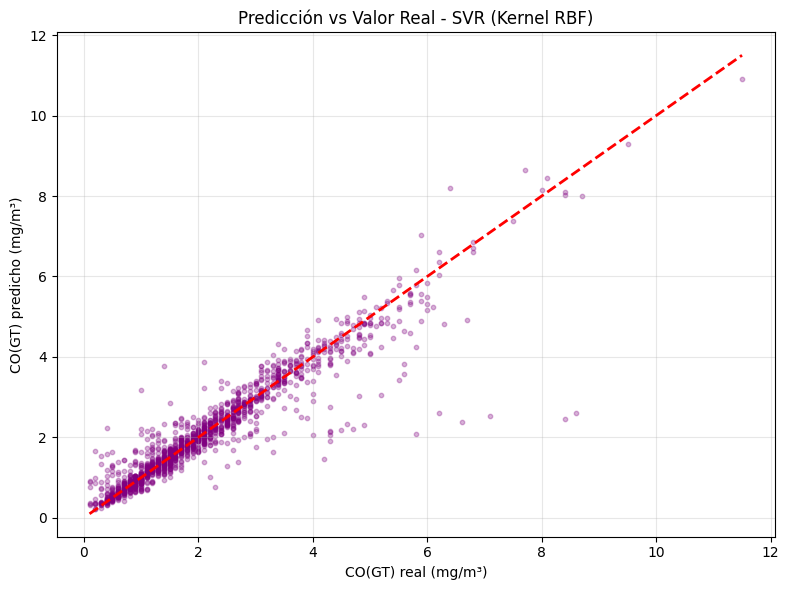

In [95]:
# Gráfico: Predicción vs Valor real
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('CO(GT) real (mg/m³)')
plt.ylabel('CO(GT) predicho (mg/m³)')
plt.title('Predicción vs Valor Real - SVR (Kernel RBF)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [96]:
# Gráfico: Análisis de residuos (error = real - predicho)
residuos = y_test - y_pred

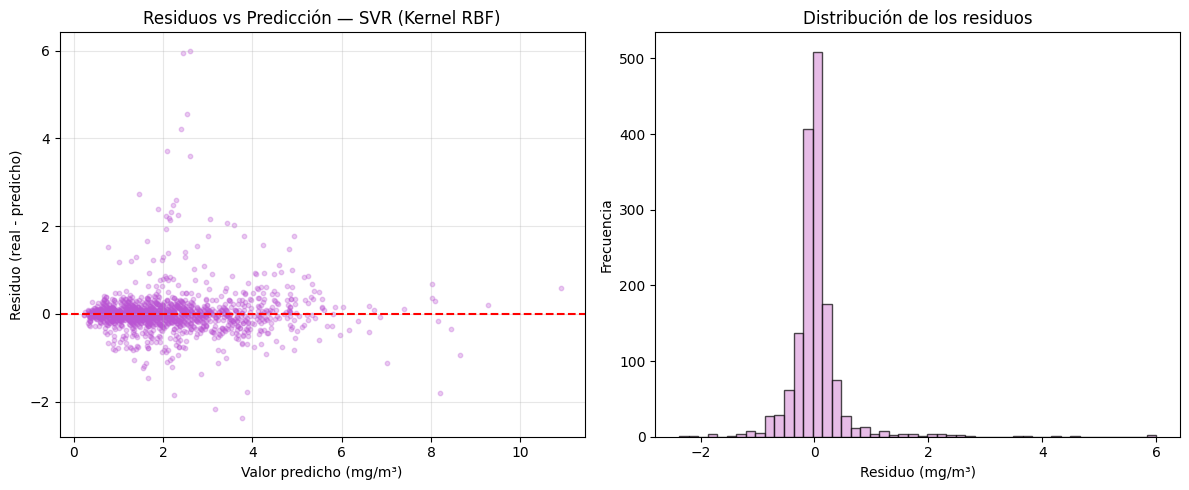

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_pred, residuos, alpha=0.3, s=10, color='mediumorchid')
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_xlabel('Valor predicho (mg/m³)')
axes[0].set_ylabel('Residuo (real - predicho)')
axes[0].set_title('Residuos vs Predicción — SVR (Kernel RBF)')
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuos, bins=50, edgecolor='black', alpha=0.7, color='plum')
axes[1].set_xlabel('Residuo (mg/m³)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Distribución de los residuos')

plt.tight_layout()
plt.show()

In [98]:
print("\n" + "="*60)
print("CONCLUSIÓN — MODELO 3: SVR (KERNEL RBF)")
print("="*60)
print("Modelo elegido: Support Vector Regression (SVR con Kernel RBF + StandardScaler)")
print("Variable objetivo: CO(GT) en mg/m³")
print("Registros usados: %d (solo filas con CO(GT) medido)" % len(df))
print("Variables predictoras: %d" % len(FEATURES))
print("")
print("Métricas sobre el conjunto de prueba (20%):")
print("   MAE  = %.4f mg/m³" % mae)
print("   MSE  = %.4f mg²/m⁶" % mse)
print("   RMSE = %.4f mg/m³" % rmse)
print("   R²   = %.4f  (objetivo: > 0.80)" % r2)
print("   MAPE = %.2f%%" % mape)
print("")
print("R² entrenamiento = %.4f | R² prueba = %.4f" % (r2_train, r2))


CONCLUSIÓN — MODELO 3: SVR (KERNEL RBF)
Modelo elegido: Support Vector Regression (SVR con Kernel RBF + StandardScaler)
Variable objetivo: CO(GT) en mg/m³
Registros usados: 7674 (solo filas con CO(GT) medido)
Variables predictoras: 18

Métricas sobre el conjunto de prueba (20%):
   MAE  = 0.2501 mg/m³
   MSE  = 0.2512 mg²/m⁶
   RMSE = 0.5012 mg/m³
   R²   = 0.8794  (objetivo: > 0.80)
   MAPE = 17.55%

R² entrenamiento = 0.8994 | R² prueba = 0.8794


In [99]:
import joblib
from google.colab import files
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

# Detecta automáticamente el Pipeline (StandardScaler + SVR) en tu cuaderno
modelo_exportar = None
for nombre_var in ['svr_pipeline', 'pipeline_svr', 'svr_model', 'modelo_svr', 'svr', 'pipe', 'model']:
    if nombre_var in globals() and isinstance(globals()[nombre_var], (Pipeline, SVR)):
        modelo_exportar = globals()[nombre_var]
        print(f"✅ Modelo SVR detectado en la variable: '{nombre_var}' ({type(modelo_exportar).__name__})")
        break

if modelo_exportar is None:
    for k, v in list(globals().items()):
        if not k.startswith('_') and isinstance(v, Pipeline):
            modelo_exportar = v
            print(f"✅ Pipeline SVR detectado en la variable: '{k}'")
            break

# Guardar y descargar (el Pipeline ya incluye el StandardScaler adentro)
joblib.dump(modelo_exportar, 'modelo_svr.joblib')
print("📦 Archivo 'modelo_svr.joblib' generado con éxito.")
files.download('modelo_svr.joblib')

✅ Modelo SVR detectado en la variable: 'svr_model' (Pipeline)
📦 Archivo 'modelo_svr.joblib' generado con éxito.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>